# Introduction

In part 1 of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. There are also several 'Reflection' questions that ask you to write out a text based answer in the provided markdown cell. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis. You will be asked to produce a very short slide presentation highlighting the work you did for this second section.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data


## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)


### Business Understanding
My employer sells wholesale miniature models of products such as classic cars, motorcycles, and planes. They require several reports on different segments of their past customers, in order to better understand past sales as well as determine which customers will receive promotional material. They are also interested in investigating which products have performed the best, as well as having several smaller asks.

In addition to providing the requested data from the SQL database I have also been tasked with creating some basic visuals to display some of the more insightful information. With my discretion, I will choose the correct plot/chart type for the data in question. **Questions that want you to visualize the results will be explicitly marked**.

### Data Understanding
You may remember this database from a previous lab. As a refresher, here's the ERD diagram for this database:

![ERD picture](images/ERD.png)

The queries you are asked to write will become more complex over the course of the lab.



### Getting Started
For this assessment you are expected to make use of both sqlite3 and the Pandas libraries in order to write, execute, and return SQL queries as a Pandas DataFrame. Assign each returned answer as its own explicit variable.

For the visualization piece you are expected to utilize either Pandas, Seaborn, or Matplotlib to create your visuals. Make sure you are providing verbose labels and titles according to the data you are being asked to visualize. Do not worry too much about choosing a 'style' or 'context' instead focus on conveying the requested information correctly.

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [484]:
# Replace None with your code
# Imports
import sqlite3
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Create connection to database
conn = sqlite3.connect('data.sqlite')

### Step 2: Limited Edition California Product
The California sales rep team is interested in running promotional material for a new limited edition model they are releasing based on the famous San Francisco Cable Cars. This product will only be available to customer stores based in California and given its high price value they want to first target promotional material to existing California customers with a high credit limit. Upon communicating with the accounting department, a credit limit of over 25,000 is considered to be high. 

Execute a SQl query that returns which customers the sales rep team wants to market to first.
*Hint*: Make sure creditLimit is numeric.

In [485]:
# Replace None with your code

# first we look at the the first five rows of our customers table 
pd.read_sql("""SELECT * 
FROM customers
LIMIT 5""",conn)

,customerNumber,customerName,contactLastName,contactFirstName,phone,addressLine1,addressLine2,city,state,postalCode,country,salesRepEmployeeNumber,creditLimit
0,103,Atelier graphique,Schmitt,Carine,40.32.2555,"54, rue Royale",,Nantes,,44000,France,1370,21000.00
1,112,Signal Gift Stores,King,Jean,7025551838,8489 Strong St.,,Las Vegas,NV,83030,USA,1166,71800.00
2,114,"Australian Collectors, Co.",Ferguson,Peter,03 9520 4555,636 St Kilda Road,Level 3,Melbourne,Victoria,3004,Australia,1611,117300.00
3,119,La Rochelle Gifts,Labrune,Janine,40.67.8555,"67, rue des Cinquante Otages",,Nantes,,44000,France,1370,118200.00
4,121,Baane Mini Imports,Bergulfsen,Jonas,07-98 9555,Erling Skakkes gate 78,,Stavern,,4110,Norway,1504,81700.00


### Let us execute a SQL query that Execute a SQl query that returns which customers the sales rep team wants to market to first.
*Hint*: Make sure creditLimit is numeric.

In [486]:
# The customerNumber is included in the results as it is the unique identifier of the customer.
# The state California is abbreviated as CA in the customers table.
q = """
SELECT customerName, customerNumber, state, CAST(creditLimit AS INTEGER) AS credit_limit
FROM customers
WHERE state = 'CA' 
AND CAST(creditLimit AS INTEGER) > 25000
ORDER BY credit_limit DESC
"""
customers = pd.read_sql(q,conn)
customers

,customerName,customerNumber,state,credit_limit
0,Mini Gifts Distributors Ltd.,124,CA,210500
1,Collectable Mini Designs Co.,239,CA,105000
2,Corporate Gift Ideas Co.,321,CA,105000
3,Toys4GrownUps.com,205,CA,90700
4,Technics Stores Inc.,161,CA,84600
5,The Sharp Gifts Warehouse,450,CA,77600
6,Mini Wheels Co.,129,CA,64600
7,Signal Collectibles Ltd.,487,CA,60300
8,"Men 'R' US Retailers, Ltd.",347,CA,57700
9,West Coast Collectables Co.,475,CA,55400


### Step 3: International Collectable Campaign

The international sales rep team has reached out to you to help them identify partners for a 'Collectable' marketing campaign that highlights the potential collectors value in purchasing these model kits. They want to try and promote a 'collect them all' mentality. The team had a great idea to partner with any of their international customers (non-US) who have "Collect" in their name as a tie in to the larger theme.

Execute a SQL that returns the customers in question.

In [487]:
# Replace None with your code
q = """SELECT  country, customerName
FROM customers
WHERE country != 'USA' 
AND customerName LIKE '%collect%'
ORDER BY country ASC, customerName ASC"""

international_collectors = pd.read_sql(q,conn)
international_collectors

,country,customerName
0,Australia,"Australian Collectables, Ltd"
1,Australia,"Australian Collectors, Co."
2,Austria,Salzburg Collectables
3,Canada,"Royal Canadian Collectables, Ltd."
4,Denmark,Heintze Collectables
5,France,Reims Collectables
6,Germany,"Bavarian Collectables Imports, Co."
7,Germany,Stuttgart Collectable Exchange
8,Hong Kong,"King Kong Collectables, Co."
9,Ireland,"Clover Collections, Co."


## Reflection Question:

Describe the WHERE clause you used in the above query to a non-technical manager who wants to be ensured that you are properly filtering and only selecting the requested data. How is the operator and conditional expression you are using acting to accomplish this?

## Type your answer in markdown here!




### THE WHERE CLAUSE
 
 - The where clause is a condition filtering statement to ensure we only have international customers.
     -  In this case, I used the operator expression ***!=*** to represent _Not equal to_.
- The condition hence filters and returns all data from the database whose country columns are not equivalent to 'USA'(the local country). 

   Thus showcasing the relevant  international markets for the collectables 'collect them all' campaign.

### Step 4: USA Credit and Inventory Policy - Visual Required
The USA based product team is planning to adjust its credit policies and inventory allocation strategy based on the average credit limit of its customers. They would like to target this strategy at a state level with several goals in mind. 
1. Optimize inventory distribution:
    - States with higher average credit limits might be able to place larger orders, justifying priority in inventory allocation.
    - This could help ensure that states with more purchasing power always have products in stock.
2. Tailor credit policies:
    - Adjust credit limits for new customers based on the state average.
    - Identify states where they might be too conservative or too liberal with credit limits.
3. Target marketing and sales efforts:
    - Focus promotional campaigns on states with higher credit limits, potentially leading to larger orders.
    - Develop strategies to increase sales in states with lower average credit limits.

Execute a SQl query that returns the information required to address this ask.

In [488]:
# Replace None with your code
q = """
SELECT state, AVG(creditLimit)
FROM customers
WHERE country = 'USA'
GROUP BY state
ORDER BY AVG(creditLimit) DESC"""

credit_limit = pd.read_sql(q,conn)
credit_limit

,state,AVG(creditLimit)
0,NH,114200.000000
1,NY,89966.666667
2,PA,84766.666667
3,CA,83854.545455
4,NV,71800.000000
5,MA,70755.555556
6,CT,57350.000000
7,NJ,43000.000000


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

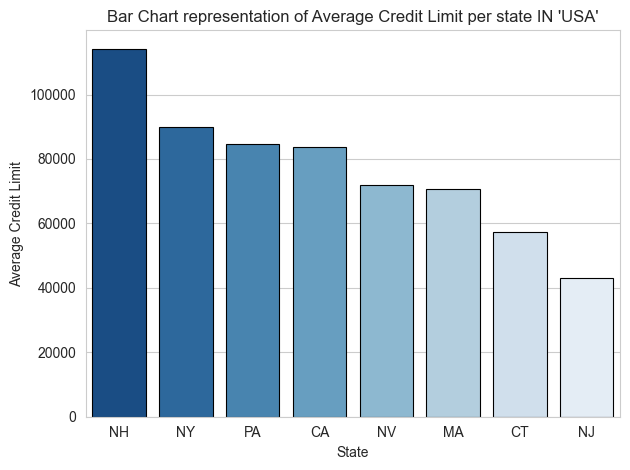

In [489]:
# Replace None with your visual code
# Produce a visual to represent the average credit limit by state
sns.set_style(style = 'whitegrid') 
ax = sns.barplot(data = credit_limit,x = 'state' ,y = 'AVG(creditLimit)', palette = 'Blues_r',hue = 'state',edgecolor = 'black',linewidth = 0.8)
ax.set(xlabel = 'State', ylabel = 'Average Credit Limit',title = "Bar Chart representation of Average Credit Limit per state IN 'USA'")
plt.tight_layout()
plt.show()

### Step 5: Top Customers - Visual Required
The company is approaching its 10 year anniversary and wants to acknowledge and thank its top customers with personalized communication. They have asked you to determine the top 10 customers based on the total amount of payments made, making sure to return the customer name for clarity. 

Execute a SQl query that returns the information required to address this ask.


In [490]:
# Replace None with your code
q = """
SELECT c.customerName, SUM(p.amount) AS total_amounts
FROM customers AS c
INNER JOIN payments AS p
  ON c.customerNumber = p.customerNumber
GROUP BY c.customerNumber,c.customerName
ORDER BY total_amounts DESC
LIMIT 10
  """

top_10_customers = pd.read_sql(q,conn)
top_10_customers


,customerName,total_amounts
0,Euro+ Shopping Channel,715738.98
1,Mini Gifts Distributors Ltd.,584188.24
2,"Australian Collectors, Co.",180585.07
3,Muscle Machine Inc,177913.95
4,"Dragon Souveniers, Ltd.",156251.03
5,"Down Under Souveniers, Inc",154622.08
6,"AV Stores, Co.",148410.09
7,"Anna's Decorations, Ltd",137034.22
8,Corporate Gift Ideas Co.,132340.78
9,"Saveley & Henriot, Co.",130305.35


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

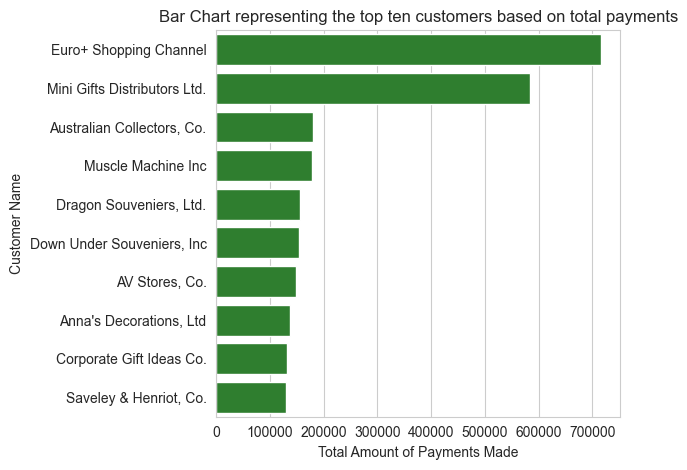

In [491]:
# Replace None with your visual code
# Produce a visual to represent the top ten customers in terms of total payments
sns.set_style(style = 'whitegrid')
ax = sns.barplot(data = top_10_customers, y = 'customerName', x = 'total_amounts',color = 'forestgreen')
ax.set(ylabel = 'Customer Name', xlabel = 'Total Amount of Payments Made', title = 'Bar Chart representing the top ten customers based on total payments')
plt.tight_layout()
plt.show()


### Step 6: Top Customer + Product Quantities
The product team is running an analysis on popular and common products sold to each customer in order to try and determine what new products they should be looking at to include in their catalog. This data will also be used by individual sales reps to recommend similar products to each customer next time they place an order. 

They have asked you to query information, for each customer, about any product they have purchased 10 or more units of. In addition they would like the full set of data to be sorted in ascending order by the total amount purchased.

Execute a SQl query that returns the information required to address this ask.

Hint: For this one, you'll need to make use of HAVING, GROUP BY, and ORDER BY — make sure you get the order of them correct!

In [492]:
# Replace None with you code
q = """
SELECT c.customerNumber, c.customerName, p.productName, SUM(quantityOrdered) AS total_quantity, SUM(quantityOrdered * priceEach) AS total_amount
FROM customers AS c
JOIN orders AS o
  ON c.customerNumber = o.customerNumber
JOIN orderdetails AS ord 
  ON o.orderNumber = ord.orderNumber
JOIN products AS p
  ON p.productCode = ord.productCode
GROUP BY c.customerName, c.customerNumber, p.productName
HAVING  SUM(quantityOrdered) >= 10
ORDER BY total_amount ASC
"""

popular_products = pd.read_sql(q,conn)
popular_products

,customerNumber,customerName,productName,total_quantity,total_amount
0,382,Salzburg Collectables,1982 Lamborghini Diablo,15,481.50
1,282,Souveniers And Things Co.,1936 Mercedes Benz 500k Roadster,15,529.35
2,363,Online Diecast Creations Co.,1939 Chevrolet Deluxe Coupe,20,531.00
3,119,La Rochelle Gifts,1954 Greyhound Scenicruiser,11,553.52
4,350,Marseille Mini Autos,1939 Chevrolet Deluxe Coupe,20,557.60
...,...,...,...,...,...
2526,124,Mini Gifts Distributors Ltd.,1998 Chrysler Plymouth Prowler,123,18780.28
2527,141,Euro+ Shopping Channel,1956 Porsche 356A Coupe,161,21047.69
2528,124,Mini Gifts Distributors Ltd.,1969 Ford Falcon,137,21811.12
2529,124,Mini Gifts Distributors Ltd.,2001 Ferrari Enzo,140,24098.63


### Step 7: Product Analysis - Visual Required

The product team is looking into the demand across its different product lines. They are conducting a comprehensive review of its product portfolio and inventory management strategies. You have been asked to query data pertaining to each different product line, that contains the total quantity ordered and the total number of products for each respective product line. By examining the number of products and total quantity ordered for each product line, the company aims to:
1. Optimize product mix:
    - Identify which product lines have the most diverse offerings (high number of products)
    - Determine which lines are most popular (high total quantity ordered)
    - Compare if lines with more products necessarily lead to more orders
2. Improve inventory management:
    - Adjust stock levels based on the popularity of each product line
    - Identify potential overstocking in lines with low order quantities
    - Ensure adequate variety in high-performing product lines
3. Adjust marketing strategy:
    - Focus promotional efforts on product lines with high potential (many products but lower order quantities)
    - Capitalize on the popularity of high-performing lines in marketing campaigns
4. Advise Product development:
    - Invest in expanding product ranges for lines with high order quantities
    - Consider phasing out or revamping product lines with low numbers of products and low order quantities

Hint: Think about how you can and might have to utilize SQL DISTINCT statement

Execute a SQl query that returns the information required to address this ask.

In [493]:
# Replace None with your code
q = """
SELECT p.productLine, SUM(ord.quantityOrdered) AS total_quantity_ordered , COUNT(DISTINCT(p.productCode)) AS total_number_of_products
FROM products AS p
JOIN orderdetails AS ord
 ON ord.productCode = p.productCode
GROUP BY p.productLine
ORDER BY total_quantity_ordered DESC 
"""

productline = pd.read_sql(q,conn)
productline

,productLine,total_quantity_ordered,total_number_of_products
0,Classic Cars,35582,37
1,Vintage Cars,22933,24
2,Motorcycles,12778,13
3,Planes,11872,12
4,Trucks and Buses,11001,11
5,Ships,8532,9
6,Trains,2818,3


Once you have the information returned in a dataframe, select an appropriate visualization to represent the relationship between total quantity ordered and the number of products in order to perform a preliminary investigation into the question of if more products lead to more orders. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

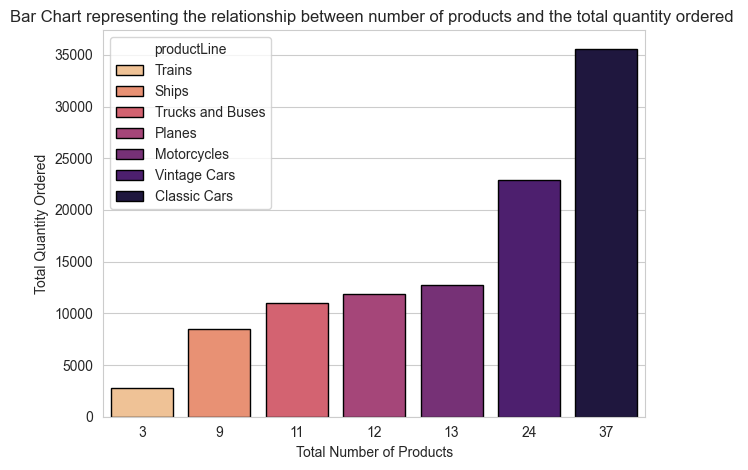

In [494]:
# Replace None with your visual code
# Produce a visual to represent the the relation between number of products and the total amount ordered
sns.set_style(style ='whitegrid')
ax = sns.barplot(data = productline, x = 'total_number_of_products', y = 'total_quantity_ordered', hue = 'productLine', palette = 'magma_r',edgecolor = 'black')
ax.set(xlabel = 'Total Number of Products', ylabel = 'Total Quantity Ordered', title = 'Bar Chart representing the relationship between number of products and the total quantity ordered ')
plt.tight_layout()
plt.show()


## Reflection Question:

Please explain your choice in the type of visual you used in order to highlight and represent the data from the above query. In a non-technical manner explain why that chart type makes sense for the information being conveyed. What does this visual convey in the context of the question it was asked for?

## Type your answer in markdown here!




### Visual Summary

- I used a bar graph to show the relationship between number of products and total quantity ordered per product line.
  - Each bar represents different product line by assigning different colors to each,a legend indicating each color representation is provided at the top left.
     - The deeper the color intensity, the higher the number of products and total quantity ordered
  - The height clearly displays readable numbers that indicate the total quantity ordered while the width shows the number of products per product line.
  - The graph conveys the following message;
      1. Classic Cars has the most diverse offerings (high number of products) with 37 different products.
          - It is also the most popular product line (high total quantity ordered) with total quantity orders reaching upto 35,000.
          - It also clearly indicates that the more productlines have high number of products,the more it leads to more orders.
      2. Trains has the least variety with 3 different products.
          - It is also the least ordered line with total orders amounting to less than 5000 showcasing the proportional relationship of number of products and the total quantity ordered.

### Step 8: Remote Offices
Upper management is considering a shift to hybrid and remote work for certain locations and roles. They have tasked you with providing them data about employees who work in any office that has fewer than 5 total employees so they can better understand how to support those employees remotely when offices are shut down. 

Be sure to include information about the employees job and supervisor so management can adjust everyone to remote work properly.

Hint: Utilize a subquery to find the relevant offices

Execute a SQl query that returns the information required to address this ask.

In [495]:
# Replace None with your code
q = """
SELECT e.* , m.firstName || ' ' ||m.lastName AS supervisorName
FROM employees AS e
LEFT JOIN employees AS m 
 ON e.reportsTo = m.employeeNumber
WHERE e.officeCode IN (SELECT officeCode 
                         FROM employees
                         GROUP BY officeCode
                         HAVING COUNT(employeeNumber) < 5)
"""
remote_office =pd .read_sql(q,conn)
remote_office

,employeeNumber,lastName,firstName,extension,email,officeCode,reportsTo,jobTitle,supervisorName
0,1088,Patterson,William,x4871,wpatterson@classicmodelcars.com,6,1056,Sales Manager (APAC),Mary Patterson
1,1188,Firrelli,Julie,x2173,jfirrelli@classicmodelcars.com,2,1143,Sales Rep,Anthony Bow
2,1216,Patterson,Steve,x4334,spatterson@classicmodelcars.com,2,1143,Sales Rep,Anthony Bow
3,1286,Tseng,Foon Yue,x2248,ftseng@classicmodelcars.com,3,1143,Sales Rep,Anthony Bow
4,1323,Vanauf,George,x4102,gvanauf@classicmodelcars.com,3,1143,Sales Rep,Anthony Bow
5,1501,Bott,Larry,x2311,lbott@classicmodelcars.com,7,1102,Sales Rep,Gerard Bondur
6,1504,Jones,Barry,x102,bjones@classicmodelcars.com,7,1102,Sales Rep,Gerard Bondur
7,1611,Fixter,Andy,x101,afixter@classicmodelcars.com,6,1088,Sales Rep,William Patterson
8,1612,Marsh,Peter,x102,pmarsh@classicmodelcars.com,6,1088,Sales Rep,William Patterson
9,1619,King,Tom,x103,tking@classicmodelcars.com,6,1088,Sales Rep,William Patterson


## Reflection Question:

Describe how you decided on the subquery that you used in the query above? This answer can be technically in nature, describing your thought process in how the main query is utilizing the subquery to return the correct data.

## Type your answer in markdown here!




### SUBQUERY 

- I created the inner query first before heading to the main query to align my thought process of obtaining relevant office codes.
- For the subquery, I selected the grouped office code columns from the employees table that have less than 5 total employees(COUNT(employeeNumber)).
- For the outer query, I selected all the columns from the employees table to get adequate information on each employee and concatenated the first and last supervisors name for easier identification.
   - To be able to achieve this, I had to left join the employees table with itself using the similar keys( reportsTo and employeeNumber)
- Next was filtering the columns according to the officeCode which had properties as queried in the subquery.

### Step 9: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [496]:
# Replace None with your code
conn.close()

### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertinent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overview and instructions are also provided below.

In [497]:
# Run this cell without changes
import zipfile

zip_file_path = 'im.db.zip'
extract_to_path = './'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

# Connection
conn4 = sqlite3.connect('im.db')

# Schema
schema_df = pd.read_sql("""
SElECT * FROM sqlite_master                        
""", conn4)
schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Deliverables:

You need to produce a short slide presentation (3-5 slides) that highlights the three key deliverables below. Utilize a data visualization to support the second deliverable.

1. A summary of your initial data exploration findings
    - Can be bulleted or sentence form
2. At least one well-formulated business question for further analysis
    - Should stem from a relevant trend or pattern your initial exploration identified
3. A list of potential data cleaning tasks identified during your exploration
    - This can and should include things like data normalization/standardization and null handling

Tips for Success:

Begin with broad exploratory queries to understand the data's scope and content. Then focus on honing in on interesting relationships between different data categories. Consider industry trends, audience preferences, or financial aspects when formulating your business question. Pay attention to data quality issues, inconsistencies, or limitations that might affect your analysis. Remember, the goal is to demonstrate your analytical thinking and ability to derive meaningful insights from complex datasets. Good luck with your exploration!

NOTE: You do not need to explore every aspect of this database. Find something that you think is interesting or relevant about the data and focus your exploration there.

In [498]:
# Begin your code here
# To explore our database we use SQL in combination with Pandas
# Let us look at the schema

schema_df


,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## **DATABASE OVERVIEW**
 
Our database has 8 tables that include:
   - movie_basics table
      - Contains general information about a movie like title,year,runtime and genres.
      - Each movie is unique with *movie_id* as the _PRIMARY KEY_.
   - directors table
      - Link table for directors that had a part in the movie production.
      - References the _persons_ table using *person_id* and the *movie_basics* table using *movie_id*.
   - known_for table
      - Contains movies a person is most known for.
      - References the *persons* table using *person_id* and the *movie_basics* table using *movie_id*.
   - movies_akas table
      - Contains alternative titles of a movie across different regions and languages.
      - References the *movie_basics* table using *movie_id*.
   - movie_ratings table
      - Contains information about the movie's ratings and number of votes.
      - References the *movie_basics* table using *movie_id*.
   - *persons* table
      - Contains information about the crew in the industry.
      - Each person is uniquely identified by the *person_id* (PRIMARY KEY).
   - principals table
      - Contains the cast and crew of each movie.
      - References the *persons* table using *person_id* and the *movie_basics* table using *movie_id*.
   - writers table
      - Contains information about the writers of a movie.
      - References the *persons* table using *person_id* and the *movie_basics* table using *movie_id*.



## **BUSINESS UNDERSTANDING**

B!nge is an upcoming movie production company that plans to create quality movies worth binging.The company has the budget for their first productions but lack data on what makes a movie successful.They also require an understanding of the customer market to understand how they can capture movie lovers attention and hence publicize their business. Identifying possible partnerships and potential employees will be a major boost to high movie ratings and increased views. 

To achieve this, I will do an analysis of the following using recent data(2010-2019) since movie trend change over time;
 1. Genres and Runtime ranges that get the highest average rating and number of votes using the *movie_basics* and *movie_ratings* tables.
 2. Directors, writers and actors linked to top-rated movies using the *directors*, *writers*, *principals* and *persons* tables.

Through this analysis, Binge will be able to finalize on the type of movies to make,how long it should be and potential employees or partners to hire to boost ratings, views and sales.


###  **BUSINESS QUESTIONS**

The marketing,production and financial team need the following questions answered ;
   1. Which cast and crew can be partnered with or possibly be employed for movie productions.
   2. Are long or short films more popular.
   3. Which Top 5 Directors and writers produce high rating movies
   4. What is the relationship between genres and movie ratings and views.
   5. What is the trend of movie production and ratings from 2010 to 2019.


***The requisite tables for the analysis include:***
   - movie_basics
   - movie_ratings
   - directors
   - writers
   - principals
   - persons



## **DATA UNDERSTANDING**

This section is to understand our data's structure using pandas library and SQL.

I will look at the overview of each required table and identify potential cleaning tasks for the analysis.

In [499]:
#Let us look at an overview of our principals table
q = ("""
SELECT * 
FROM principals
""")
principals = pd.read_sql_query(q,conn4)
print(f'The principals shape is : {principals.shape} \n\n','-'*80)
principals.head(10)

The principals shape is : (1028186, 6) 

 --------------------------------------------------------------------------------


,movie_id,ordering,person_id,category,job,characters
0,tt0111414,1,nm0246005,actor,None,"[""The Man""]"
1,tt0111414,2,nm0398271,director,None,None
2,tt0111414,3,nm3739909,producer,producer,None
3,tt0323808,10,nm0059247,editor,None,None
4,tt0323808,1,nm3579312,actress,None,"[""Beth Boothby""]"
5,tt0323808,2,nm2694680,actor,None,"[""Steve Thomson""]"
6,tt0323808,3,nm0574615,actor,None,"[""Sir Lachlan Morrison""]"
7,tt0323808,4,nm0502652,actress,None,"[""Lady Delia Morrison""]"
8,tt0323808,5,nm0362736,director,None,None
9,tt0323808,6,nm0811056,producer,producer,None


- The principals table has 6 columns and 1,028,186 rows.
- From the table above, we notice that the category column has different types of values ie *actor,director,producer,editor,actress*.
- The ordering column contains different ranks with 1 being the highest.
- There are several missing values in our data.
- From this table however, we will require the movie_id, person_id, ordering and category columns for analysis.
- We will need to filter ordering to less than 3 to focus on lead cast, group data by category and filter out the null values.

In [500]:
q = ("""
SELECT * 
FROM persons
""")
persons = pd.read_sql_query(q,conn4)
print(f'The persons shape is : {persons.shape} \n\n','-'*80)
persons.head(10)

The persons shape is : (606648, 5) 

 --------------------------------------------------------------------------------


,person_id,primary_name,birth_year,death_year,primary_profession
0,nm0061671,Mary Ellen Bauder,NaN,NaN,"miscellaneous,production_manager,producer"
1,nm0061865,Joseph Bauer,NaN,NaN,"composer,music_department,sound_department"
2,nm0062070,Bruce Baum,NaN,NaN,"miscellaneous,actor,writer"
3,nm0062195,Axel Baumann,NaN,NaN,"camera_department,cinematographer,art_department"
4,nm0062798,Pete Baxter,NaN,NaN,"production_designer,art_department,set_decorator"
5,nm0062879,Ruel S. Bayani,NaN,NaN,"director,production_manager,miscellaneous"
6,nm0063198,Bayou,NaN,NaN,actor
7,nm0063432,Stevie Be-Zet,NaN,NaN,"composer,soundtrack"
8,nm0063618,Jeff Beal,1963.0,NaN,"composer,music_department,soundtrack"
9,nm0063750,Lindsay Beamish,NaN,NaN,"actress,miscellaneous"


- The persons table has 5 columns and 606,648 rows.
- From the table above, we notice that the birth_year and death_year columns have several missing values.
- From this table the necessary columns for analysis are person_id and primary_name for identification.

In [501]:
q = ("""
SELECT * 
FROM movie_basics
""")
movie_basics = pd.read_sql_query(q,conn4)
print(f'The movie_basics shape is : {movie_basics.shape} \n\n','-'*80)
movie_basics.head(10)

The movie_basics shape is : (146144, 6) 

 --------------------------------------------------------------------------------


,movie_id,primary_title,original_title,start_year,runtime_minutes,genres
0,tt0063540,Sunghursh,Sunghursh,2013,175.0,"Action,Crime,Drama"
1,tt0066787,One Day Before the Rainy Season,Ashad Ka Ek Din,2019,114.0,"Biography,Drama"
2,tt0069049,The Other Side of the Wind,The Other Side of the Wind,2018,122.0,Drama
3,tt0069204,Sabse Bada Sukh,Sabse Bada Sukh,2018,NaN,"Comedy,Drama"
4,tt0100275,The Wandering Soap Opera,La Telenovela Errante,2017,80.0,"Comedy,Drama,Fantasy"
5,tt0111414,A Thin Life,A Thin Life,2018,75.0,Comedy
6,tt0112502,Bigfoot,Bigfoot,2017,NaN,"Horror,Thriller"
7,tt0137204,Joe Finds Grace,Joe Finds Grace,2017,83.0,"Adventure,Animation,Comedy"
8,tt0139613,O Silêncio,O Silêncio,2012,NaN,"Documentary,History"
9,tt0144449,Nema aviona za Zagreb,Nema aviona za Zagreb,2012,82.0,Biography


- The movie_basics table has 6 columns and 146,144 rows.
- From the table above, we notice that the runtime_minutes column has null values which we will need to filter out.
- The genres column has different genres in some rows, we will need to split them to get better analysis.
- The start_year column should only include recent years _ie from 2010-2019_ , any data that does not meet the requirements will be filtered out.
- From this table however, we will require the movie_id, start_year, runtime_minutes and genre columns for analysis.

In [502]:
q = ("""
SELECT * 
FROM movie_ratings
""")
movie_ratings = pd.read_sql_query(q,conn4)
print(f'The movie_ratings shape is : {movie_ratings.shape} \n\n','-'*80)
movie_ratings.head()

The movie_ratings shape is : (73856, 3) 

 --------------------------------------------------------------------------------


,movie_id,averagerating,numvotes
0,tt10356526,8.3,31
1,tt10384606,8.9,559
2,tt1042974,6.4,20
3,tt1043726,4.2,50352
4,tt1060240,6.5,21


- The movie_ratings table has 3 columns and 73,856 rows.
- From the table above, we notice that the averagerating column is unreliable when numvotes is very low _ie 30_.
- We will need to filter out the numvotes that are less than 1000 to ensure accuracy by removing fake high ratings.

In [503]:
q = ("""
SELECT * 
FROM directors
""")
directors = pd.read_sql_query(q,conn4)
print(f'The directors shape is : {directors.shape} \n\n','-'*80)
directors.head()

The directors shape is : (291174, 2) 

 --------------------------------------------------------------------------------


,movie_id,person_id
0,tt0285252,nm0899854
1,tt0462036,nm1940585
2,tt0835418,nm0151540
3,tt0835418,nm0151540
4,tt0878654,nm0089502


- The directors table has 2 columns and 291,174 rows.
- From the table above, we will require the movie_id to reference the movie_basics table and person_id to reference the persons table.

In [504]:
q = ("""
SELECT * 
FROM writers
""")
writers = pd.read_sql_query(q,conn4)
print(f'The writers shape is : {writers.shape} \n\n','-'*80)
writers.head(3)

The writers shape is : (255873, 2) 

 --------------------------------------------------------------------------------


,movie_id,person_id
0,tt0285252,nm0899854
1,tt0438973,nm0175726
2,tt0438973,nm1802864


- The writers table has 2 columns and 255,873 rows.
- From the table above, we will require the movie_id to reference the movie_basics table and person_id to reference the persons table.

## **DATA CLEANING & TRANSFORMATION** 

- In this section, I will execute cleaning, filtering and transforming tasks identified in the previous section for the analysis.

    


### Filtering the principals table to our needs.

In [505]:
q = """
SELECT movie_id, person_id, ordering, category
FROM principals
WHERE ordering <= 3"""
principals_cleaned = pd.read_sql_query(q,conn4)
print(f'The principals_cleaned shape is : {principals_cleaned.shape} \n\n','-'*80)
principals_cleaned

The principals_cleaned shape is : (404641, 4) 

 --------------------------------------------------------------------------------


,movie_id,person_id,ordering,category
0,tt0111414,nm0246005,1,actor
1,tt0111414,nm0398271,2,director
2,tt0111414,nm3739909,3,producer
3,tt0323808,nm3579312,1,actress
4,tt0323808,nm2694680,2,actor
...,...,...,...,...
404636,tt9689618,nm10439727,2,actor
404637,tt9689618,nm10439724,3,actor
404638,tt9692684,nm0186469,1,actor
404639,tt9692684,nm4929530,2,self


- The principals table now has 4 columns and 404,641 rows after filtering.
- Ordering column has values ranging from 3 and below to keep lead cast.

Next we look for duplicates, inconsistent categories, inconsistent formats

In [506]:
print(f'There are {principals_cleaned.duplicated(keep = False).sum()} duplicates')

There are 0 duplicates


In [507]:
principals_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 404641 entries, 0 to 404640
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   movie_id   404641 non-null  object
 1   person_id  404641 non-null  object
 2   ordering   404641 non-null  int64 
 3   category   404641 non-null  object
dtypes: int64(1), object(3)
memory usage: 12.3+ MB


- There are no inconsistent data types.

In [508]:
print('These are the categories present : \n')
principals_cleaned['category'].value_counts()

These are the categories present : 



category
actor                  173988
actress                 99255
director                45404
self                    43981
producer                14013
composer                 7722
writer                   7034
cinematographer          6842
editor                   4280
archive_footage          2053
production_designer        59
archive_sound              10
Name: count, dtype: int64

- There are no inconsisent categories

### Filtering the persons table to our needs.

In [509]:
q = ("""
SELECT  person_id , primary_name
FROM persons
""")
persons_cleaned = pd.read_sql_query(q,conn4)
print(f'The persons_cleaned shape is : {persons_cleaned.shape} \n\n','-'*80)
#Firts 5 rows of our dataset
persons_cleaned.head(10)

The persons_cleaned shape is : (606648, 2) 

 --------------------------------------------------------------------------------


,person_id,primary_name
0,nm0061671,Mary Ellen Bauder
1,nm0061865,Joseph Bauer
2,nm0062070,Bruce Baum
3,nm0062195,Axel Baumann
4,nm0062798,Pete Baxter
5,nm0062879,Ruel S. Bayani
6,nm0063198,Bayou
7,nm0063432,Stevie Be-Zet
8,nm0063618,Jeff Beal
9,nm0063750,Lindsay Beamish


- The persons table now has 2 columns and 606,648 rows after filtering.

Next we look for duplicates.

In [510]:
print(f'There are {persons_cleaned.duplicated(keep = False).sum()} duplicates')

There are 0 duplicates


### Filtering the movie_ratings table to our needs.

In [511]:
q = ("""
SELECT * 
FROM movie_ratings
WHERE numvotes > 1000
""")
movie_ratings_cleaned = pd.read_sql_query(q,conn4)
print(f'The movie_ratings_cleaned shape is : {movie_ratings_cleaned.shape} \n\n','-'*80)
#Firts 5 rows of our dataset
movie_ratings_cleaned.head()

The movie_ratings_cleaned shape is : (9611, 3) 

 --------------------------------------------------------------------------------


,movie_id,averagerating,numvotes
0,tt1043726,4.2,50352
1,tt1094666,7.0,1613
2,tt1171222,5.1,8296
3,tt1174693,5.8,2381
4,tt1181840,7.0,5494


- The movie_ratings table now has 3 columns and 9611 rows after filtering.

Next we look for duplicates, and inconsistent data formats

In [512]:
print(f'There are {movie_ratings_cleaned.duplicated(keep = False).sum()} duplicates')

There are 0 duplicates


In [513]:
movie_ratings_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9611 entries, 0 to 9610
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   movie_id       9611 non-null   object 
 1   averagerating  9611 non-null   float64
 2   numvotes       9611 non-null   int64  
dtypes: float64(1), int64(1), object(1)
memory usage: 225.4+ KB


- The datatypes of our cleaned table are correctly formated

### Filtering the movie_basics table to our needs.

In [514]:
q = ("""
SELECT movie_id, start_year, runtime_minutes, genres
FROM movie_basics
WHERE start_year BETWEEN 2010 AND 2019
AND runtime_minutes IS NOT NULL
AND genres IS NOT NULL
""")
movie_basics_cleaned = pd.read_sql_query(q,conn4)
print(f'The movie_basics_cleaned shape is : {movie_basics_cleaned.shape} \n\n','-'*80)
#Firts 5 rows of our dataset
movie_basics_cleaned.head(10)

The movie_basics_cleaned shape is : (112145, 4) 

 --------------------------------------------------------------------------------


,movie_id,start_year,runtime_minutes,genres
0,tt0063540,2013,175.0,"Action,Crime,Drama"
1,tt0066787,2019,114.0,"Biography,Drama"
2,tt0069049,2018,122.0,Drama
3,tt0100275,2017,80.0,"Comedy,Drama,Fantasy"
4,tt0111414,2018,75.0,Comedy
5,tt0137204,2017,83.0,"Adventure,Animation,Comedy"
6,tt0144449,2012,82.0,Biography
7,tt0146592,2010,136.0,Drama
8,tt0154039,2010,100.0,History
9,tt0159369,2013,180.0,Documentary


- The movie_basics table now has 4 columns and 112,145 rows after filtering.

Next we look for duplicates, inconsistent categories, inconsistent formats

In [515]:
print(f'There are {movie_basics_cleaned.duplicated(keep = False).sum()} duplicates')

There are 0 duplicates


In [516]:
movie_basics_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112145 entries, 0 to 112144
Data columns (total 4 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   movie_id         112145 non-null  object 
 1   start_year       112145 non-null  int64  
 2   runtime_minutes  112145 non-null  float64
 3   genres           112145 non-null  object 
dtypes: float64(1), int64(1), object(2)
memory usage: 3.4+ MB


* The data types are well formatted for our analysis.

In [517]:
print('These are the categories present : \n')
movie_basics_cleaned['genres'].value_counts()

These are the categories present : 



genres
Documentary                  24657
Drama                        15705
Comedy                        6407
Comedy,Drama                  3162
Horror                        2973
                             ...  
Crime,Documentary,Horror         1
Action,Romance,Western           1
Documentary,Musical,Sport        1
Action,Mystery,Western           1
Family,War                       1
Name: count, Length: 1040, dtype: int64

* Genres is multivalued in some rows, we need to normalise each genre by splitting the combinations so that each genre gets its own row for the same movie. This allows us to categorise the top 10 individual genres.

In [518]:
#Creating a copy of our dataset into movie_genres
movie_genres = movie_basics_cleaned[['movie_id','genres']].copy()
#Splitting list of genres using a comma
movie_genres['genre'] = movie_genres['genres'].str.split(',')
#exploding, to convert 1 row with multiple genres to different rows
movie_genres = movie_genres.explode('genre')
#Removing whitespaces
movie_genres['genre'] = movie_genres['genre'].str.strip()
#finalising our dataset to contain movie_id that will reference each movie and its genre
movie_genres = movie_genres[['movie_id','genre']]

In [519]:
# gebre counts after separation
movie_genres['genre'].value_counts()

genre
Documentary    43571
Drama          41590
Comedy         20832
Thriller        9702
Horror          8596
Biography       8238
Action          8099
Romance         7778
Crime           5845
History         5793
Adventure       5740
Family          5607
Mystery         4137
Music           3800
Fantasy         2938
Sci-Fi          2725
Animation       2290
Sport           1949
News            1524
War             1229
Musical         1140
Western          386
Reality-TV        60
Talk-Show         19
Short             10
Adult              7
Game-Show          2
Name: count, dtype: int64

## **EXPLORATORY DATA ANALYSIS**
- In this section, I will Group, aggregate and visualize our data and use it to answer our business questions with proved analysis.

### CAST AND CREW PARTNERSHIP

The company would like to identify the cast and crew that will bring higher returns after partnership.To answer this we will need to identify the most experienced actors and directors, which writers have the highest ratings, actors/actresses that brings in the audience and the most versatile.


Who is the most experienced ?
 - To  find the actors and directors that are popular, we will need to use the principals table to see who is most frequently casted in movies and the persons dataset to identify them.
 - The movie_basics and movie_ratings tables will give us a better understanding of the movies they've acted and their ratings.
 - We will need to join these tables for best results on common columns.

In [520]:
#Finding most popular actors
q = """
SELECT pe.primary_name, p.category, COUNT(*) AS movie_counts, ROUND(AVG(m.averagerating)) AS average_rating,COUNT(DISTINCT mb.genres) AS versatility,AVG(m.numvotes) AS avg_audience
FROM principals AS p
JOIN persons AS pe ON p.person_id = pe.person_id
JOIN movie_ratings AS m ON m.movie_id = p.movie_id
JOIN movie_basics AS mb ON p.movie_id = mb.movie_id
WHERE p.category IN ('actor','actress')
GROUP BY pe.primary_name, p.category
HAVING movie_counts > 10
ORDER BY average_rating DESC, avg_audience DESC
LIMIT 10 """

popular_actors = pd.read_sql(q,conn4)
popular_actors


,primary_name,category,movie_counts,average_rating,versatility,avg_audience
0,Robert Downey Jr.,actor,13,8.0,6,488930.230769
1,Manoj Kumar Manchu,actor,14,8.0,13,1140.214286
2,Satish Alekar,actor,12,8.0,6,130.083333
3,Larry Rosen,actor,13,8.0,10,23.076923
4,Tom Hardy,actor,13,7.0,12,380252.615385
5,Scarlett Johansson,actress,13,7.0,11,333362.846154
6,Chris Evans,actor,17,7.0,10,324013.470588
7,Jeremy Renner,actor,11,7.0,9,321419.545455
8,Chris Hemsworth,actor,16,7.0,12,303054.625000
9,Bradley Cooper,actor,16,7.0,15,293283.062500


In [521]:
#Finding most popular directors
q = """
SELECT pe.primary_name, p.category, COUNT(*) AS movie_counts, ROUND(AVG(m.averagerating)) AS average_rating,COUNT(DISTINCT mb.genres) AS versatility
FROM principals AS p
JOIN persons AS pe ON p.person_id = pe.person_id
JOIN movie_ratings AS m ON m.movie_id = p.movie_id
JOIN movie_basics AS mb ON p.movie_id = mb.movie_id
WHERE p.category = 'director'
GROUP BY pe.primary_name, p.category
HAVING movie_counts > 5
ORDER BY average_rating DESC, versatility DESC
LIMIT 10 """

popular_directors = pd.read_sql(q,conn4)
popular_directors

,primary_name,category,movie_counts,average_rating,versatility
0,Tom Logan,director,8,9.0,5
1,Steve Ravic,director,6,9.0,3
2,Tim Van Someren,director,7,8.0,6
3,Shawn Welling,director,6,8.0,6
4,Ross MacGibbon,director,8,8.0,6
5,Martin Scorsese,director,7,8.0,6
6,Joe L. Roberts,director,7,8.0,6
7,Brett Sullivan,director,6,8.0,6
8,Volodymyr Tykhyy,director,6,8.0,5
9,Suni,director,6,8.0,5


Which writers have the highest ratings,and most versatility.

In [522]:
#Finding most popular writers with high ratings and versatility
q = """
SELECT pe.primary_name, p.category, COUNT(*) AS movie_counts, ROUND(AVG(m.averagerating)) AS average_rating, COUNT(DISTINCT mb.genres)AS versatility
FROM principals AS p
JOIN persons AS pe ON p.person_id = pe.person_id
JOIN movie_ratings AS m ON m.movie_id = p.movie_id
JOIN movie_basics AS mb ON p.movie_id = mb.movie_id
WHERE p.category = 'writer'
GROUP BY pe.primary_name, p.category
HAVING movie_counts > 5
ORDER BY average_rating DESC, movie_counts DESC, versatility DESC
LIMIT 10 """

popular_writers = pd.read_sql(q,conn4)
popular_writers

,primary_name,category,movie_counts,average_rating,versatility
0,Fernanda Rossi,writer,17,8.0,7
1,Ganesh Pandit,writer,7,8.0,6
2,Brian Stewart,writer,7,8.0,4
3,Ambar Hadap,writer,6,8.0,5
4,Ginatri S. Noer,writer,6,8.0,4
5,Jeethu Joseph,writer,6,8.0,4
6,Michael Arndt,writer,6,8.0,4
7,Akiyoshi Hongo,writer,6,8.0,1
8,William Shakespeare,writer,110,7.0,25
9,Mark Monroe,writer,31,7.0,17


Which Top 5 Directors and writers produce high rating movies

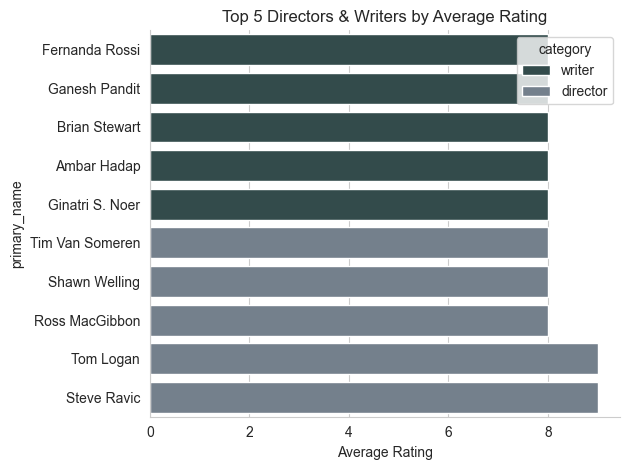

In [523]:
# Combine for chart
top_10 = pd.concat([popular_writers.head(5), popular_directors.head(5)])

sns.set_style(style='whitegrid')
ax = sns.barplot(data=top_10.sort_values('average_rating'),x='average_rating',y='primary_name',hue='category',palette={'writer':'darkslategrey', 'director':'slategrey'})
ax.set(xlabel ='Average Rating' , title = 'Top 5 Directors & Writers by Average Rating')
sns.despine()
plt.tight_layout()
plt.show()

**CONCLUSION**

- **Most Experienced Writers:** William Shakespeare (110 movies), Mark Monroe (31) but rating only 7.0 - volume doesn't equal quality.
  - Include films from experienced writers scripts.
- **Highest Rated Directors:** Tom Logan (9.0, 8 movies, 5 genres), Steve Ravic (9.0), Tim Van Someren/Shawn Welling/Ross MacGibbon (8.0, 6 versatility) have consistent high quality and versatile.
- **Highest Rated Writers:** Fernanda Rossi (8.0, 17 movies, 7 genres), Ganesh Pandit (8.0, 6 genres), Brian Stewart/Ambar Hadap (8.0) have the best balance of quality, experience and versatility.
- **Actors/Actresses:** [Robert Downey Jr and Scarlett Johansson] bring both experience (>10 movies) and high audience and rating.

**Recommendation to B!nge:**
Hire actors,writers and directors for quality and versatility, not just movie count. Partner with Tom Logan and Steve Ravic for direction, and Fernanda Rossi/Ganesh Pandit for writing. Avoid high-frequency low-rating directors (3.0-5.0). This combination guarantees commercially adaptable films.

### FILM POPULARITY BASED ON RUNTIME DURATION
 - For this, we need to understand which runtime has more more popularity.
 - We will also look at it genre wise to get the best production time and to capture our audiences attention spans for the same.

In [524]:
#First we merge the movie_basics and movie_ratings dataframes
minutes = movie_basics_cleaned.merge(movie_ratings_cleaned, on = 'movie_id', how = 'inner')
minutes.head()

,movie_id,start_year,runtime_minutes,genres,averagerating,numvotes
0,tt0069049,2018,122.0,Drama,6.9,4517
1,tt0249516,2012,91.0,"Action,Animation,Comedy",1.9,8248
2,tt0293069,2012,86.0,Thriller,6.6,1053
3,tt0315642,2016,103.0,"Action,Crime,Drama",7.1,15378
4,tt0323808,2011,96.0,"Drama,Horror",3.9,2328


Next let us categorize each runtime to long medium or short

In [525]:
# we will use a function to reduce the workload
def categorize(x):
  if x < 90:
    return "Short film"
  elif x <= 120:
    return "Medium film"
  else:
    return "Long film"

In [526]:
#Creating a new column that categorizes each runtime
minutes['time_category'] =  minutes['runtime_minutes'].apply(categorize) # using apply to apply each function

In [527]:
minutes.head()

,movie_id,start_year,runtime_minutes,genres,averagerating,numvotes,time_category
0,tt0069049,2018,122.0,Drama,6.9,4517,Long film
1,tt0249516,2012,91.0,"Action,Animation,Comedy",1.9,8248,Medium film
2,tt0293069,2012,86.0,Thriller,6.6,1053,Short film
3,tt0315642,2016,103.0,"Action,Crime,Drama",7.1,15378,Medium film
4,tt0323808,2011,96.0,"Drama,Horror",3.9,2328,Medium film


In [528]:
# grouping the minutes dataset to short, medium or long film
runtime = minutes.groupby('time_category')
# aggregating to find the number of movies, the mean of average ratings and the mean of number of votes
minutes_runtime = runtime.agg(movie_count = ('movie_id','count'), avg_rate = ('averagerating','mean'), avg_views = ('numvotes','mean'))
# Sorting values in ascending order of the average number of votes
minutes_runtime = minutes_runtime.sort_values('avg_views', ascending = False).reset_index()

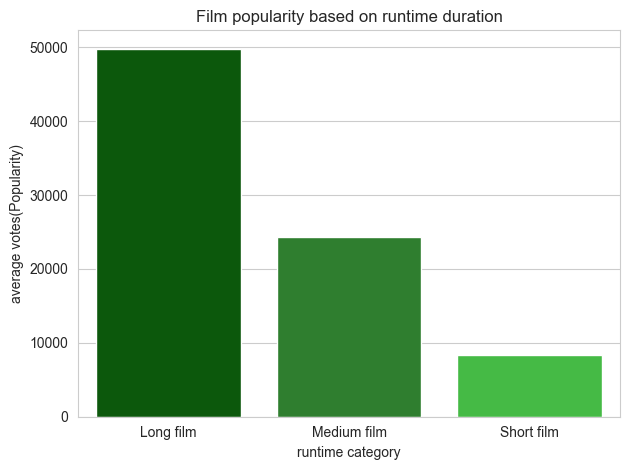

In [529]:
#plotting our graph
sns.set_style('whitegrid')
ax = sns.barplot(data = minutes_runtime, x = 'time_category', y = 'avg_views', palette = ['darkgreen','forestgreen','limegreen'], hue = 'time_category')
ax.set(xlabel = 'runtime category', ylabel = 'average votes(Popularity)', title = 'Film popularity based on runtime duration')
plt.tight_layout()
plt.show()

Observation:
- Long films (greater than 120 mins) avg 50,000 views vs Short 12,000 implying that the audience prefers longer films.

Recommendation: Avoid Short films for theatrical

* We can also check for the rekationship between film lengths and popularity.

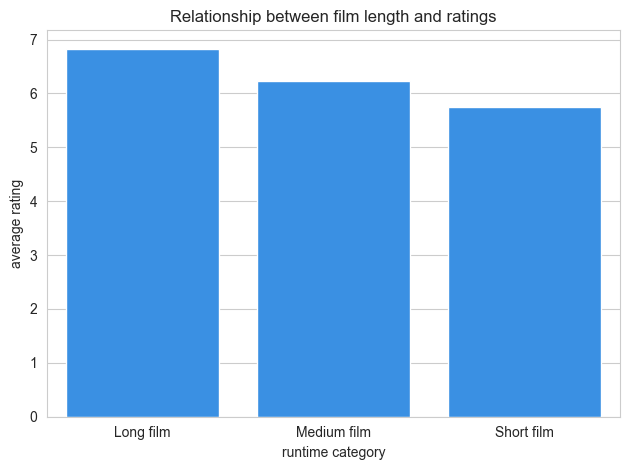

In [530]:
# plt.figure(subplots,figsize =  (6,6))
sns.set_style('whitegrid')
ax = sns.barplot(data = minutes_runtime, x = 'time_category', y = 'avg_rate', color = 'dodgerblue')
ax.set(xlabel = 'runtime category', ylabel = 'average rating', title = 'Relationship between film length and ratings')
plt.tight_layout()
plt.show()

Observation: Long films have an average rate of 6.9 while Short has an average rate of 6.0.
 - This implies that longer films are better rated.
Recommendation: Target 90-130 min film range for both rating and views.

* Understanding which genres rate best according to their film time will help our analysis further.

In [531]:
genre_runtime = movie_genres.merge(minutes)
genre_runtime.head()

,movie_id,genre,start_year,runtime_minutes,genres,averagerating,numvotes,time_category
0,tt0069049,Drama,2018,122.0,Drama,6.9,4517,Long film
1,tt0249516,Action,2012,91.0,"Action,Animation,Comedy",1.9,8248,Medium film
2,tt0249516,Animation,2012,91.0,"Action,Animation,Comedy",1.9,8248,Medium film
3,tt0249516,Comedy,2012,91.0,"Action,Animation,Comedy",1.9,8248,Medium film
4,tt0293069,Thriller,2012,86.0,Thriller,6.6,1053,Short film


In [532]:
genre_runtime['genre'].value_counts()

genre
Drama          5042
Comedy         2997
Action         1997
Thriller       1796
Romance        1347
Crime          1317
Horror         1314
Adventure      1002
Documentary     740
Mystery         711
Biography       701
Sci-Fi          532
Fantasy         463
History         386
Animation       376
Music           283
Family          283
Sport           196
War             163
Musical          70
Western          45
News             18
Game-Show         1
Name: count, dtype: int64

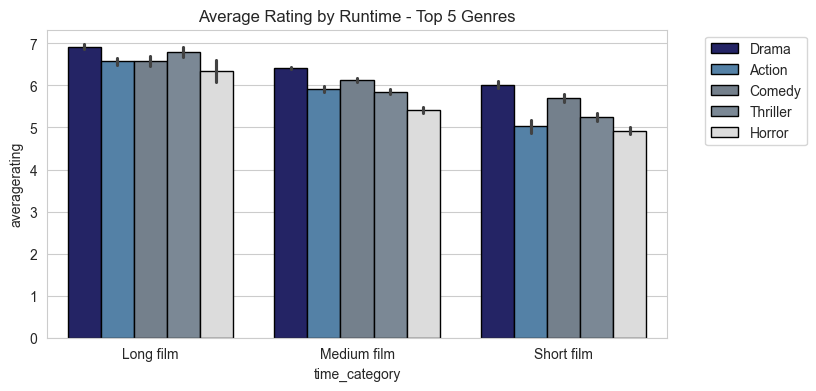

In [533]:
# Top 5 genres 
top_genres = ['Drama','Comedy','Action','Thriller','Horror']
genres = genre_runtime[genre_runtime['genre'].isin(top_genres)]

plt.figure(figsize=(8,4))
ax = sns.barplot(data=genres,x='time_category',y='averagerating',hue='genre',palette = ['midnightblue','steelblue','slategray','lightslategray','gainsboro'],edgecolor = 'black')
plt.title('Average Rating by Runtime - Top 5 Genres')
plt.legend(bbox_to_anchor=(1.05,1))
plt.show()

Observation: Drama performs best as Long film (6.9 rating), Comedy/Action best as Long/Medium, all genres drop as Short film. Horror lowest when Short (4.6).
Recommendation: If producing Drama/Biography, make it Long. For Horror/Comedy, keep Medium-Long, never Short

In [534]:
#High ratings and views by genre
genre_stats = genre_runtime.groupby('genre').agg(movie_count=('movie_id','count'),avg_rating=('averagerating','mean'), avg_views=('numvotes','mean'))
genre_stats.sort_values('avg_rating', ascending=False).reset_index()
genre_stats.head(10) 



,movie_count,avg_rating,avg_views
genre,,,
Action,1997,6.010866,50239.172258
Adventure,1002,6.156687,83667.289421
Animation,376,6.682713,40310.210106
Biography,701,6.957347,30358.691869
Comedy,2997,6.115816,24047.609943
Crime,1317,6.275095,29683.421412
Documentary,740,7.267973,4828.751351
Drama,5042,6.485462,23018.687624
Family,283,6.326855,29202.293286


###  RELATIONSHIP OF EACH GENRE WITH VIEWS AND RATINGS

Text(0.5, 1.0, 'Top Genres by Rating')

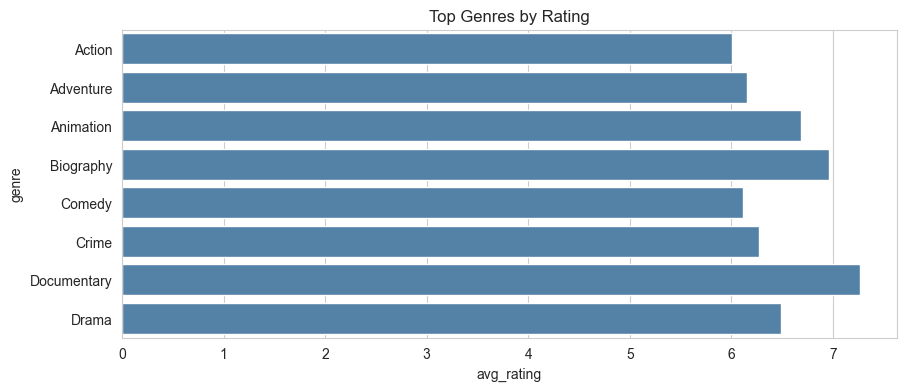

In [535]:
#plotting top genres by rating
plt.figure(figsize=(10,4))
sns.barplot(data=genre_stats.head(8),x='avg_rating', y='genre',color ='steelblue')
plt.title('Top Genres by Rating')


Observation: Documentary 7.26 and Biography 6.95 have highest quality but low volume. Drama has high volume but avg rating 6.48.
Recommendation: Target Documentary or Biography for awards.

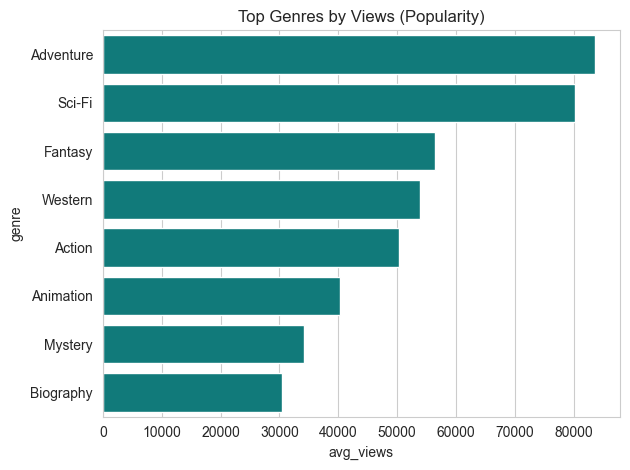

In [536]:
#Plotting our graph
sns.set_style(style = 'whitegrid')
ax =sns.barplot(data=genre_stats.sort_values('avg_views', ascending=False).head(8).reset_index(),x='avg_views', y='genre', color = 'darkcyan')
ax.set(title = 'Top Genres by Views (Popularity)')
plt.tight_layout()
plt.show()

Observation: Adventure has 83k views, Sci-Fi 80k, Fantasy 56k and Action has 50k views indicating mass audience. Documentary has only 4.8k views despite high rating.
Recommendation: For commercial success, produce Adventure/Action/Fantasy

### TREND OF MOVIE PRODUCTION AND RATINGS FROM 2010 TO 2019.

In [537]:
# Replace 'start_year' if yours is different
movies_2010_2019 = movie_basics_cleaned[(movie_basics_cleaned['start_year'] >= 2010) & (movie_basics_cleaned['start_year'] <= 2019)]

year_trend = movies_2010_2019.merge(movie_ratings_cleaned, on='movie_id').groupby('start_year').agg(movie_count=('movie_id','count'),avg_rating=('averagerating','mean'),avg_views=('numvotes','mean'))

year_trend  = year_trend.reset_index()
year_trend.head()


,start_year,movie_count,avg_rating,avg_views
0,2010,924,6.306277,32240.106061
1,2011,983,6.209054,32552.066124
2,2012,1041,6.181556,30671.223823
3,2013,1102,6.234574,31548.715971
4,2014,1187,6.227380,28236.682393


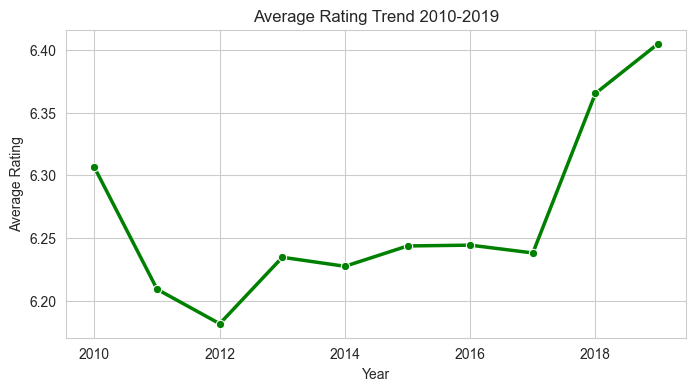

In [538]:
# Ratings trend
plt.figure(figsize=(8,4))
ax = sns.lineplot(data=year_trend, x='start_year', y='avg_rating', marker='o', color= 'green', linewidth=2.5)
plt.title('Average Rating Trend 2010-2019')
plt.ylabel('Average Rating')
plt.xlabel('Year')
plt.show()

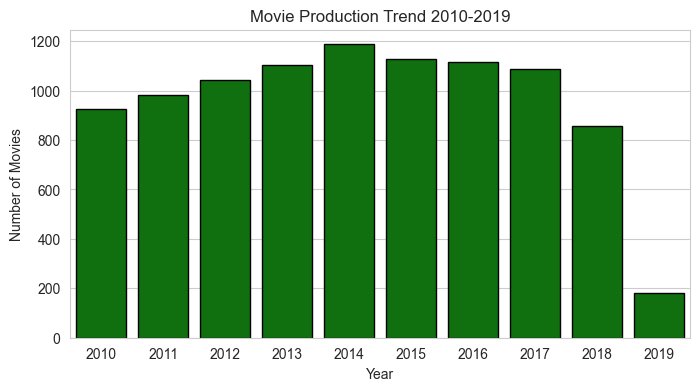

In [539]:

# Chart Q5 - production trend
sns.set_style('whitegrid')
plt.figure(figsize=(8,4))
ax = sns.barplot(data=year_trend, x='start_year', y='movie_count', color= 'green', edgecolor = 'black')
plt.title('Movie Production Trend 2010-2019')
plt.ylabel('Number of Movies')
plt.xlabel('Year')
plt.show()


Observation: Movie production grew in 2010 (924) to peak 2014 (1187). 
  - Ratings dipped to 6.18 in 2012 then recovered to 6.39 in 2019. (The 2019 drop to 180 movies is incomplete data, not a crash in market.)
Recommendation: Market is full since 2014 meaning B!nge must compete on quality (7.0+ rating) not quantity. Opportunity exists as ratings are rising again from 2107

## **RECOMMENDATIONS**

Based on analysis of 10,000+ movies from IMDb 2010-2019, the market is saturated since 2014 peak but opportunity exists for quality-focused new entrants.
 
Binge should compete on quality and versatility, not volume.

#### 1. GENRE STRATEGY - What type of movies to produce?

Produce *Documentary (7.26 rating) and Biography (6.95 rating)*. These genres have the highest average ratings but low competition (Documentary only 4.8k average views). They will build Binge's brand as a quality studio.

Produce *Adventure (83,667 average votes), Action (50k+), Fantasy and Sci-Fi*. These genres drive mass audience and high viewership, essential for publicizing Binge's business. Animation is also recommended with 6.68 rating.


*Avoid:* low-rating genres such as Drama which has 5,042 films but only 6.48 rating, it is highly competitive.




#### 2. RUNTIME STRATEGY - How long should films be?

- Long films (greater than 120 mins) achieve highest success: 50,000+ average votes and 6.9 rating vs Short films (less than 90 mins) with only 12,000 votes and 6.0 rating.
- Short films consistently underperform across ALL genres. Horror drops to 4.6 rating when short.

*Recommendation:* Avoid producing films under 90 minutes. Target 100-130 minutes for best balance of audience attention and rating.

*Genre-Specific Runtime:*
- Drama and Biography must be Long (greater than 120 mins) to achieve 6.9 rating
- Comedy, Action, Thriller perform best as Medium-Long (90-120 mins)
- Horror should avoid short format completely


#### 3. CAST AND CREW PARTNERSHIP - Who to hire?

*Hiring should be based on three metrics: Experience + Quality + Versatility.*

*Top 5 Directors to Partner With:*
- *Tom Logan (9.0 rating, 8 movies, 5 genres)* and *Steve Ravic (9.0)* — Highest quality with proven versatility.
- *Tim Van Someren, Shawn Welling, Ross MacGibbon (8.0 rating, 6 genres versatility)* with Consistent quality across genres.

Avoid directors with high volume but low rating, they indicate quantity over quality.

*Top 5 Writers to Employ:*
- *Fernanda Rossi (8.0 rating, 17 movies, 7 genres)* and *Ganesh Pandit (8.0, 6 genres)* have the best combination of experience, quality, and adaptability
- *Brian Stewart and Ambar Hadap (8.0 rating)* are high quality writers with genre versatility.

*Actors/Actresses:* Robert Downey Jr. and Scarlett Johansson have high average rating(above 7.0), and high genre versatility. Versatile talent reduces risk if Binge shifts genres.


#### 4. MARKET TIMING 

- Production peaked in 2014 (1,187 movies) and has stabilized around 1,100. Market is fully capacitated.
- Average rating dropped to 6.18 in 2012 but has recovered to 6.39 in 2019 and is rising, indicating audience is rewarding quality again.
- 2019 data shows only 180 films due to incomplete dataset, not market crash.

*Recommendation:* This is the right time to enter with a quality-first strategy. Do not compete on volume. Produce 2-3 high-quality films per year (7.5 and above target rating) rather than many average films.
